# Sentiment Analysis of Movie Reviews Using Neural Networks

## Objective
To develop a neural network model that classifies movie reviews as positive or negative using natural language processing techniques.

## Dataset
The project uses the IMDb Large Movie Review Dataset for training and evaluation. Reviews published on Decoders will be explored separately to examine how the model performs on reviews from our own publication.

## Technologies Used
- Python
- Google Colab
- TensorFlow/Keras
- Pandas
- Scikit-learn

## Methodology
1. Load and explore the dataset.
2. Preprocess the text data.
3. Convert text into numerical representations.
4. Build and train a neural network.
5. Evaluate the model using appropriate performance metrics.
6. Test the model on new movie reviews.

In [1]:
import sys

print("Python version:", sys.version)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [3]:
from tensorflow.keras.datasets import imdb

vocab_size = 10000

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(
    num_words=vocab_size
)

print("Training reviews:", len(train_data))
print("Testing reviews:", len(test_data))
print("First review label:", train_labels[0])
print("First review encoded sequence:", train_data[0][:20])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training reviews: 25000
Testing reviews: 25000
First review label: 1
First review encoded sequence: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]


In [4]:
import numpy as np

unique, counts = np.unique(train_labels, return_counts=True)

print("Sentiment distribution in training data:")

for label, count in zip(unique, counts):
    sentiment = "Negative" if label == 0 else "Positive"
    print(f"{sentiment}: {count}")

print("\nTotal training reviews:", len(train_labels))

Sentiment distribution in training data:
Negative: 12500
Positive: 12500

Total training reviews: 25000


In [7]:
review_lengths = [len(review) for review in train_data]

print("Shortest review:", min(review_lengths), "words")
print("Longest review:", max(review_lengths), "words")
print("Average review length:", round(np.mean(review_lengths), 2), "words")

Shortest review: 11 words
Longest review: 2494 words
Average review length: 238.71 words


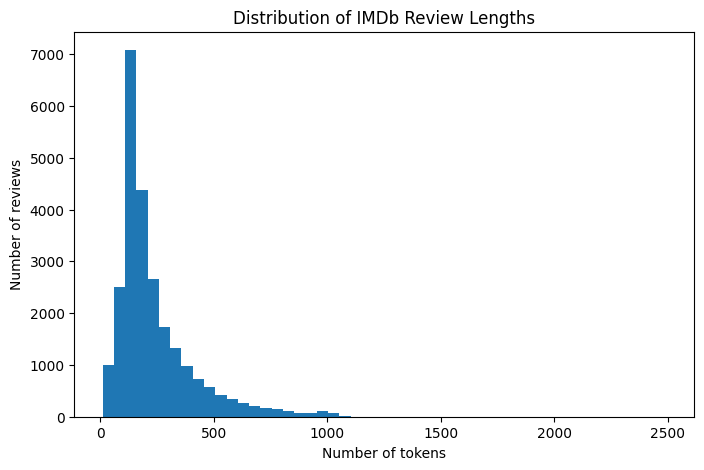

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(review_lengths, bins=50)
plt.title("Distribution of IMDb Review Lengths")
plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.show()

In [9]:
word_index = imdb.get_word_index()

index_word = {
    index + 3: word
    for word, index in word_index.items()
}

index_word[0] = "<PAD>"
index_word[1] = "<START>"
index_word[2] = "<UNK>"
index_word[3] = "<UNUSED>"

def decode_review(encoded_review):
    return " ".join(
        index_word.get(token, "<UNK>")
        for token in encoded_review
    )

print("Encoded review:")
print(train_data[0][:30])

print("\nDecoded review:")
print(decode_review(train_data[0])[:1000])

print("\nSentiment:", "Positive" if train_labels[0] == 1 else "Negative")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Encoded review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480]

Decoded review:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were j

In [10]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_length = 200

X_train = pad_sequences(
    train_data,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    test_data,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

y_train = np.array(train_labels)
y_test = np.array(test_labels)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (25000, 200)
Testing data shape: (25000, 200)
Training labels shape: (25000,)
Testing labels shape: (25000,)


In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split

In [12]:
model = Sequential([
    Embedding(input_dim=10000, output_dim=32, mask_zero=True),
    GlobalAveragePooling1D(),
    Dense(16, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.build(input_shape=(None, 200))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,545 (1.22 MB)

 Trainable params: 320,545 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train_final))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 20000
Validation samples: 5000
Testing samples: 25000


In [14]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_final,
    y_train_final,
    epochs=10,
    batch_size=512,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.6205 - loss: 0.6865 - val_accuracy: 0.7256 - val_loss: 0.6744
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.7250 - loss: 0.6507 - val_accuracy: 0.7566 - val_loss: 0.6214
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.7715 - loss: 0.5815 - val_accuracy: 0.7980 - val_loss: 0.5408
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.8094 - loss: 0.4965 - val_accuracy: 0.8224 - val_loss: 0.4646
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - accuracy: 0.8357 - loss: 0.4293 - val_accuracy: 0.8286 - val_loss: 0.4130
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.8527 - loss: 0.3802 - val_accuracy: 0.8436 - val_loss: 0.3792
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.8632 - loss: 0.3475 - val_accuracy: 0.8488 - val_loss: 0.3588
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.8776 - loss: 0.3190 - val_accuracy: 0.8558 - v

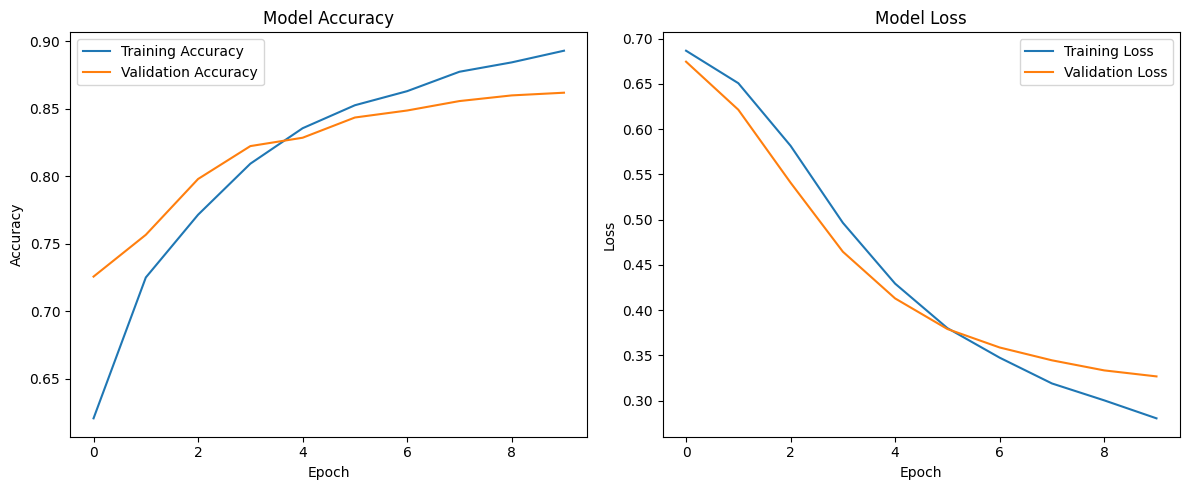

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [16]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8596 - loss: 0.3267
Test Accuracy: 85.96%
Test Loss: 0.3267


782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step
Classification Report:

              precision    recall  f1-score   support

    Negative       0.86      0.86      0.86     12500
    Positive       0.86      0.86      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



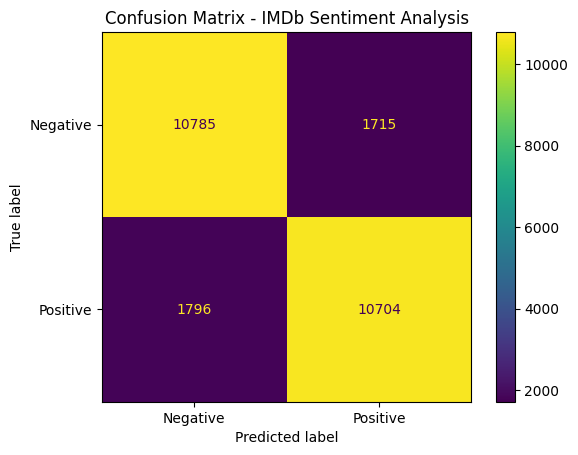

In [17]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Generate predictions
y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).flatten()

# Classification report
print("Classification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot()
plt.title("Confusion Matrix - IMDb Sentiment Analysis")
plt.show()

In [21]:
def predict_sentiment(review):
    # Tokenize the review
    words = review.lower().split()

    # IMDb reserves indices 0-3 for special tokens
    encoded_review = [1]

    for word in words:
        index = word_index.get(word)

        if index is None or index >= 9997:
            encoded_review.append(2)
        else:
            encoded_review.append(index + 3)

    # Pad or truncate the sequence
    padded_review = pad_sequences(
        [encoded_review],
        maxlen=200,
        padding="post",
        truncating="post"
    )

    # Predict sentiment
    probability = float(model.predict(padded_review, verbose=0)[0][0])

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive sentiment probability: {probability:.4f}")

In [22]:
predict_sentiment(
    "This movie was fantastic with excellent performances and a brilliant story"
)

Review: This movie was fantastic with excellent performances and a brilliant story
Predicted sentiment: Positive
Positive sentiment probability: 1.0000


In [23]:
predict_sentiment(
    "This movie was boring with terrible acting and a disappointing story"
)

Review: This movie was boring with terrible acting and a disappointing story
Predicted sentiment: Negative
Positive sentiment probability: 0.0000


In [24]:
# Inspect the prediction probabilities
print("Positive review probability:")
print(model.predict(
    pad_sequences(
        [[1] + [
            word_index.get(word, 2) + 3
            if word in word_index and word_index[word] < 9997
            else 2
            for word in "this movie was fantastic with excellent performances and a brilliant story".split()
        ]],
        maxlen=200,
        padding="post",
        truncating="post"
    ),
    verbose=0
))

print("\nNegative review probability:")
print(model.predict(
    pad_sequences(
        [[1] + [
            word_index.get(word, 2) + 3
            if word in word_index and word_index[word] < 9997
            else 2
            for word in "this movie was boring with terrible acting and a disappointing story".split()
        ]],
        maxlen=200,
        padding="post",
        truncating="post"
    ),
    verbose=0
))

Positive review probability:
[[0.9999622]]

Negative review probability:
[[7.5809686e-07]]


In [25]:
import re
import string
from tensorflow.keras.preprocessing.sequence import pad_sequences

def encode_review(review):
    # Convert to lowercase and remove punctuation
    review = review.lower()
    review = review.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Split into words
    words = review.split()

    # Convert words into IMDb vocabulary indices
    encoded = [1]  # Start-of-review token

    for word in words:
        index = word_index.get(word)

        if index is None or index >= 9997:
            encoded.append(2)  # Unknown-word token
        else:
            encoded.append(index + 3)

    # Match the input shape used during training
    encoded = pad_sequences(
        [encoded],
        maxlen=200,
        padding="post",
        truncating="post"
    )

    return encoded

In [26]:
def predict_sentiment(review):
    encoded_review = encode_review(review)

    probability = float(
        model.predict(encoded_review, verbose=0)[0][0]
    )

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive sentiment probability: {probability:.4f}")

In [27]:
predict_sentiment(
    "This movie was fantastic! The performances were excellent."
)

predict_sentiment(
    "This movie was boring. The acting was terrible and disappointing."
)

Review: This movie was fantastic! The performances were excellent.
Predicted sentiment: Positive
Positive sentiment probability: 0.9998
Review: This movie was boring. The acting was terrible and disappointing.
Predicted sentiment: Negative
Positive sentiment probability: 0.0000


In [28]:
predict_sentiment(
    "The acting was excellent, but the story was boring and predictable."
)

Review: The acting was excellent, but the story was boring and predictable.
Predicted sentiment: Negative
Positive sentiment probability: 0.0051


In [29]:
from google.colab import files

uploaded = files.upload()

Saving decoders_reviews_updated.csv to decoders_reviews_updated.csv


In [30]:
import pandas as pd

decoders_df = pd.read_csv("decoders_reviews_updated.csv")

print("Total reviews:", len(decoders_df))
print("\nDataset columns:")
print(decoders_df.columns.tolist())

print("\nReview titles and sentiment labels:")
print(decoders_df[["title", "sentiment"]].to_string(index=False))

Total reviews: 7

Dataset columns:
['title', 'review', 'sentiment', 'source', 'use_for_binary_evaluation', 'notes']

Review titles and sentiment labels:
                                                              title sentiment
           Obsession Review: When a Wish for Love Turns Into Horror  positive
The Disclosure Day: What Happens After We Discover We're Not Alone?     mixed
                      The Odyssey Review: When Two Mammoths Collide     mixed
     Spider-Man: Brand New Day Is a Love Letter to Every Spidey Fan  positive
       The Devil Wears Prada 2: How the World of Runway Has Changed     mixed
                                             Carrie (Mike Flanagan)  positive
                                                      The Godfather  positive


In [31]:
decoders_results = []

for _, row in decoders_df.iterrows():
    encoded_review = encode_review(row["review"])

    probability = float(
        model.predict(encoded_review, verbose=0)[0][0]
    )

    prediction = "positive" if probability >= 0.5 else "negative"

    decoders_results.append({
        "title": row["title"],
        "actual_sentiment": row["sentiment"],
        "predicted_sentiment": prediction,
        "positive_probability": round(probability, 4)
    })

results_df = pd.DataFrame(decoders_results)

print(results_df.to_string(index=False))

                                                              title actual_sentiment predicted_sentiment  positive_probability
           Obsession Review: When a Wish for Love Turns Into Horror         positive            positive                0.8912
The Disclosure Day: What Happens After We Discover We're Not Alone?            mixed            positive                0.9183
                      The Odyssey Review: When Two Mammoths Collide            mixed            positive                0.6279
     Spider-Man: Brand New Day Is a Love Letter to Every Spidey Fan         positive            positive                0.9120
       The Devil Wears Prada 2: How the World of Runway Has Changed            mixed            positive                0.7922
                                             Carrie (Mike Flanagan)         positive            negative                0.4513
                                                      The Godfather         positive            positive       

In [32]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Model architecture
lstm_model = Sequential([
    Embedding(
        input_dim=10000,
        output_dim=128,
        input_length=200,
        mask_zero=True
    ),

    Bidirectional(
        LSTM(64, dropout=0.2)
    ),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

# Compile the model
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [34]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 205s 656ms/step - accuracy: 0.8808 - loss: 0.2900 - val_accuracy: 0.8610 - val_loss: 0.3367
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 197s 630ms/step - accuracy: 0.9180 - loss: 0.2135 - val_accuracy: 0.8592 - val_loss: 0.3403
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 194s 622ms/step - accuracy: 0.9405 - loss: 0.1636 - val_accuracy: 0.8520 - val_loss: 0.3882


In [35]:
print("Completed epochs:", len(history_lstm.history["loss"]))

print("Validation losses:")
print(history_lstm.history["val_loss"])

print("Best validation loss:")
print(min(history_lstm.history["val_loss"]))

Completed epochs: 3
Validation losses:
[0.33665549755096436, 0.3403262197971344, 0.3881648778915405]
Best validation loss:
0.33665549755096436


In [36]:
test_loss, test_accuracy = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"LSTM Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"LSTM Test Loss: {test_loss:.4f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 57s 72ms/step - accuracy: 0.8458 - loss: 0.3701
LSTM Test Accuracy: 84.58%
LSTM Test Loss: 0.3701


782/782 ━━━━━━━━━━━━━━━━━━━━ 61s 76ms/step
LSTM Classification Report:

              precision    recall  f1-score   support

    Negative       0.84      0.86      0.85     12500
    Positive       0.85      0.84      0.84     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



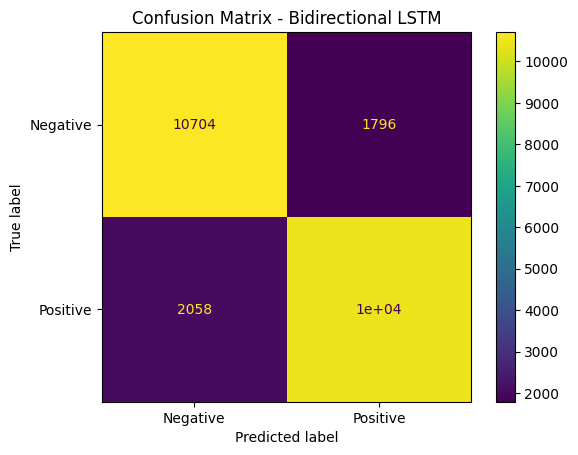

In [37]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict sentiment for the test dataset
y_prob_lstm = lstm_model.predict(X_test, verbose=1)

# Convert probabilities into binary predictions
y_pred_lstm = (y_prob_lstm >= 0.5).astype(int).flatten()

# Display classification report
print("LSTM Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_lstm,
    target_names=["Negative", "Positive"]
))

# Generate confusion matrix
cm_lstm = confusion_matrix(y_test, y_pred_lstm)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_lstm,
    display_labels=["Negative", "Positive"]
)

cm_display.plot()
plt.title("Confusion Matrix - Bidirectional LSTM")
plt.show()

In [38]:
def predict_sentiment_lstm(review):
    # Convert the review into the format expected by the model
    encoded_review = encode_review(review)

    # Predict positive sentiment probability
    probability = float(
        lstm_model.predict(encoded_review, verbose=0)[0][0]
    )

    # Classify the review
    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probability:.4f}")

In [39]:
predict_sentiment_lstm(
    "This movie was fantastic with excellent performances and a brilliant story."
)

predict_sentiment_lstm(
    "This movie was boring with terrible acting and a disappointing story."
)

Review: This movie was fantastic with excellent performances and a brilliant story.
Predicted sentiment: Positive
Positive probability: 0.9902
Review: This movie was boring with terrible acting and a disappointing story.
Predicted sentiment: Negative
Positive probability: 0.0045


In [40]:
decoders_results_lstm = []

for _, row in decoders_df.iterrows():
    encoded_review = encode_review(row["review"])

    probability = float(
        lstm_model.predict(encoded_review, verbose=0)[0][0]
    )

    prediction = "positive" if probability >= 0.5 else "negative"

    decoders_results_lstm.append({
        "title": row["title"],
        "actual_sentiment": row["sentiment"],
        "predicted_sentiment": prediction,
        "positive_probability": round(probability, 4)
    })

results_lstm_df = pd.DataFrame(decoders_results_lstm)

print(results_lstm_df.to_string(index=False))

                                                              title actual_sentiment predicted_sentiment  positive_probability
           Obsession Review: When a Wish for Love Turns Into Horror         positive            negative                0.4259
The Disclosure Day: What Happens After We Discover We're Not Alone?            mixed            positive                0.6616
                      The Odyssey Review: When Two Mammoths Collide            mixed            negative                0.2606
     Spider-Man: Brand New Day Is a Love Letter to Every Spidey Fan         positive            positive                0.9185
       The Devil Wears Prada 2: How the World of Runway Has Changed            mixed            positive                0.5820
                                             Carrie (Mike Flanagan)         positive            negative                0.0657
                                                      The Godfather         positive            positive       

In [41]:
lstm_model.save("decoders_sentiment_lstm.keras")

print("LSTM model saved successfully!")

LSTM model saved successfully!


In [42]:
from google.colab import files

files.download("decoders_sentiment_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>